| Признак | Тип | Описание |
|---|---|---|
| `v1`–`v8` | Categorical | Анонимизированные переменные кредитной заявки |
| `has_fico` | Binary | Наличие кредитного рейтинга FICO |
| `business_channel` | Categorical | Канал выдачи кредита (1, 2 или 3) |
| `fico_score` | Numeric | Стандартизированный кредитный рейтинг FICO; 0 означает отсутствие значения |
| `loan_amount` | Numeric | Стандартизированная сумма кредита |
| `monthly_income` | Numeric | Стандартизированный ежемесячный доход заёмщика |
| `age` | Numeric | Стандартизированный возраст заёмщика |
| `gearing_coefficient` | Numeric | Стандартизированный коэффициент долговой нагрузки |
| `max_gearing_ratio` | Numeric | Стандартизированный максимально допустимый коэффициент долговой нагрузки |
| `default` | Binary | Целевая переменная: просрочка платежа на 45 и более дней (1 — да, 0 — нет) |

# Загрузка данных и первичный просмотр

In [2]:
import pandas as pd
from empulse.datasets import load_vub_credit_scoring

dataset = load_vub_credit_scoring(backend=pd)

X = dataset.data
y = dataset.target

df = X.copy()
df['default'] = y
df.head()

,v1,v2,v3,v4,v5,v6,v7,v8,has_fico,business_channel,fico_score,loan_amount,monthly_income,age,gearing_coefficient,max_gearing_ratio,default
0,1,2,6,4,5,1,1,2,1,1,1.498183,0.204811,0.383312,1.107163,-0.718249,1.796590,0
1,2,3,11,5,7,7,1,2,1,1,-0.241731,-0.852651,-0.732430,1.406664,1.122930,-0.768631,0
2,3,3,10,4,2,4,1,2,0,1,0.000000,-0.676407,-0.057350,0.957412,-1.702482,0.513980,1
3,1,3,5,2,4,4,1,3,0,1,0.000000,-0.412042,-0.574648,-0.390342,0.910077,-0.768631,0
4,1,3,11,2,5,4,3,4,0,2,0.000000,0.557299,-0.210623,-0.390342,-0.384496,0.513980,0


In [3]:
print(f"Размерность датасета: {df.shape}")

Размерность датасета: (18917, 17)


In [4]:
from pathlib import Path

data_dir = Path('../data/raw')
data_dir.mkdir(parents=True, exist_ok=True)

df.to_csv(data_dir/'vub_credit_scoring.csv', index=False)

In [5]:
df = pd.read_csv(data_dir/'vub_credit_scoring.csv')
df.head()

,v1,v2,v3,v4,v5,v6,v7,v8,has_fico,business_channel,fico_score,loan_amount,monthly_income,age,gearing_coefficient,max_gearing_ratio,default
0,1,2,6,4,5,1,1,2,1,1,1.498183,0.204811,0.383312,1.107163,-0.718249,1.796590,0
1,2,3,11,5,7,7,1,2,1,1,-0.241731,-0.852651,-0.732430,1.406664,1.122930,-0.768631,0
2,3,3,10,4,2,4,1,2,0,1,0.000000,-0.676407,-0.057350,0.957412,-1.702482,0.513980,1
3,1,3,5,2,4,4,1,3,0,1,0.000000,-0.412042,-0.574648,-0.390342,0.910077,-0.768631,0
4,1,3,11,2,5,4,3,4,0,2,0.000000,0.557299,-0.210623,-0.390342,-0.384496,0.513980,0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18917 entries, 0 to 18916
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   v1                   18917 non-null  int64  
 1   v2                   18917 non-null  int64  
 2   v3                   18917 non-null  int64  
 3   v4                   18917 non-null  int64  
 4   v5                   18917 non-null  int64  
 5   v6                   18917 non-null  int64  
 6   v7                   18917 non-null  int64  
 7   v8                   18917 non-null  str    
 8   has_fico             18917 non-null  int64  
 9   business_channel     18917 non-null  int64  
 10  fico_score           18917 non-null  float64
 11  loan_amount          18917 non-null  float64
 12  monthly_income       18917 non-null  float64
 13  age                  18917 non-null  float64
 14  gearing_coefficient  18917 non-null  float64
 15  max_gearing_ratio    18917 non-null  float64
 1

In [7]:
df.describe()

,v1,v2,v3,v4,v5,v6,v7,has_fico,business_channel,fico_score,loan_amount,monthly_income,age,gearing_coefficient,max_gearing_ratio,default
count,18917.000000,18917.000000,18917.000000,18917.000000,18917.000000,18917.000000,18917.000000,18917.000000,18917.000000,1.891700e+04,18917.000000,18917.000000,18917.000000,18917.000000,18917.000000,18917.000000
mean,1.851721,3.495956,8.796902,3.295237,3.862082,4.799598,1.787968,0.574193,1.351377,6.188637e-12,-0.000076,0.000014,-0.000094,-0.000045,-0.000027,0.169477
std,1.085406,1.220051,3.825752,1.337009,2.015629,1.310071,0.965753,0.494478,0.655482,7.577401e-01,0.999972,1.000025,0.999943,1.000007,1.000019,0.375183
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,-6.033156e+00,-1.117017,-0.984880,-1.588346,-2.869484,-0.768631,0.000000
25%,1.000000,3.000000,6.000000,2.000000,2.000000,4.000000,1.000000,0.000000,1.000000,-2.665865e-01,-0.676407,-0.485614,-0.839594,-0.758691,-0.768631,0.000000
50%,1.000000,3.000000,10.000000,4.000000,4.000000,5.000000,1.000000,1.000000,1.000000,0.000000e+00,-0.323920,-0.246688,-0.090841,0.255554,-0.768631,0.000000
75%,3.000000,5.000000,11.000000,4.000000,6.000000,5.000000,3.000000,1.000000,2.000000,1.311079e-01,0.381055,0.189466,0.807662,0.908658,0.513980,0.000000
max,5.000000,6.000000,16.000000,6.000000,7.000000,7.000000,3.000000,1.000000,3.000000,2.467563e+00,5.844611,43.842002,2.080541,9.387304,1.796590,1.000000


In [8]:
df.duplicated().sum()

np.int64(1)

Видим наличие дубликата. Посмотрим на него

In [9]:
df[df.duplicated()]

,v1,v2,v3,v4,v5,v6,v7,v8,has_fico,business_channel,fico_score,loan_amount,monthly_income,age,gearing_coefficient,max_gearing_ratio,default
18055,3,3,15,2,4,4,3,1,0,1,0.0,0.557299,-0.348119,-1.139095,0.852606,-0.768631,0


Удалим дубликат

In [10]:
df.drop_duplicates()

,v1,v2,v3,v4,v5,v6,v7,v8,has_fico,business_channel,fico_score,loan_amount,monthly_income,age,gearing_coefficient,max_gearing_ratio,default
0,1,2,6,4,5,1,1,2,1,1,1.498183,0.204811,0.383312,1.107163,-0.718249,1.796590,0
1,2,3,11,5,7,7,1,2,1,1,-0.241731,-0.852651,-0.732430,1.406664,1.122930,-0.768631,0
2,3,3,10,4,2,4,1,2,0,1,0.000000,-0.676407,-0.057350,0.957412,-1.702482,0.513980,1
3,1,3,5,2,4,4,1,3,0,1,0.000000,-0.412042,-0.574648,-0.390342,0.910077,-0.768631,0
4,1,3,11,2,5,4,3,4,0,2,0.000000,0.557299,-0.210623,-0.390342,-0.384496,0.513980,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18912,4,4,10,4,4,5,1,1,0,1,0.000000,-0.676407,-0.346992,1.406664,-1.392993,-0.768631,0
18913,3,5,12,2,4,5,3,3,0,1,0.000000,0.557299,-0.317689,-0.015966,0.713188,-0.768631,0
18914,1,5,10,3,4,5,1,3,0,1,0.000000,-0.500164,-0.412358,-0.540093,0.250232,-0.768631,0
18915,4,5,10,4,4,5,1,1,0,1,0.000000,0.557299,-0.348119,1.107163,0.852606,-0.768631,0


Посмотрим есть ли какие-то пропуски в данных

In [11]:
df.isna().sum()

v1                     0
v2                     0
v3                     0
v4                     0
v5                     0
v6                     0
v7                     0
v8                     0
has_fico               0
business_channel       0
fico_score             0
loan_amount            0
monthly_income         0
age                    0
gearing_coefficient    0
max_gearing_ratio      0
default                0
dtype: int64

Пропусков нет, может начать анализ целевой переменной

# EDA для целевой переменной

Посмотрим баланс классов

In [12]:
values = df['default'].value_counts()
values

default
0    15711
1     3206
Name: count, dtype: int64

Видим сильный дисбаланс классов. Посмотрим на процентное соотношение классов

In [25]:
df['default'].value_counts(normalize=True) * 100

default
0    83.052281
1    16.947719
Name: proportion, dtype: float64

Как видим, заемщики, которе имеют просрочку более 45 дней составляют всего 16%. Следовательно, использовать `accuracy` точно нельзя
Посчитаем коэффициент дисбаланса классов ($IR = N_0 / N_1$)

In [14]:
print(f"Коэффициент дисбаланса равен: {values[0] / values[1]:.4f}")

Коэффициент дисбаланса равен: 4.9005


Мы наблюдаем умеренный дисбаланс классов, будет целесообразно добавить `weighted_classes`, и за основные метрики взять Recall, Precision и PR-AUC

# EDA признаков

Начнем с eda анонимизированных признаков, по описанию они у нас категориальные. Поэтому сначала посмотрим на количество каждой категории в признаках

In [19]:
for v in [df[f'v{i}'] for i in range(1, 9)]:
    print(v.value_counts(normalize=True), f"количество уникальных элементов: {v.nunique()}", sep='\n', end='\n\n')

v1
1    0.591531
3    0.279431
4    0.081197
2    0.047365
5    0.000476
Name: proportion, dtype: float64
количество уникальных элементов: 5

v2
3    0.360892
5    0.251361
4    0.241899
1    0.109373
2    0.034836
6    0.001639
Name: proportion, dtype: float64
количество уникальных элементов: 6

v3
10    0.298303
11    0.275942
2     0.119469
3     0.060528
15    0.038801
14    0.036581
12    0.036158
5     0.030925
7     0.028757
1     0.019295
13    0.017762
4     0.015859
8     0.013321
6     0.007084
9     0.001163
16    0.000053
Name: proportion, dtype: float64
количество уникальных элементов: 16

v4
4    0.390284
2    0.194164
5    0.185759
1    0.136438
3    0.093197
6    0.000159
Name: proportion, dtype: float64
количество уникальных элементов: 6

v5
2    0.210287
7    0.182481
3    0.173759
4    0.152508
1    0.112967
5    0.088122
6    0.079875
Name: proportion, dtype: float64
количество уникальных элементов: 7

v6
5    0.387482
4    0.342285
7    0.182640
3    0.041550
2   

Видим что равномерно распределенных признаков нет, и практически в каждом признаке есть категории составляющие меньше 1%, объединим эти категории в одну категорию `Other`, после разделения на train и test выборки

Посмотрим также на графики распределения этих признаков

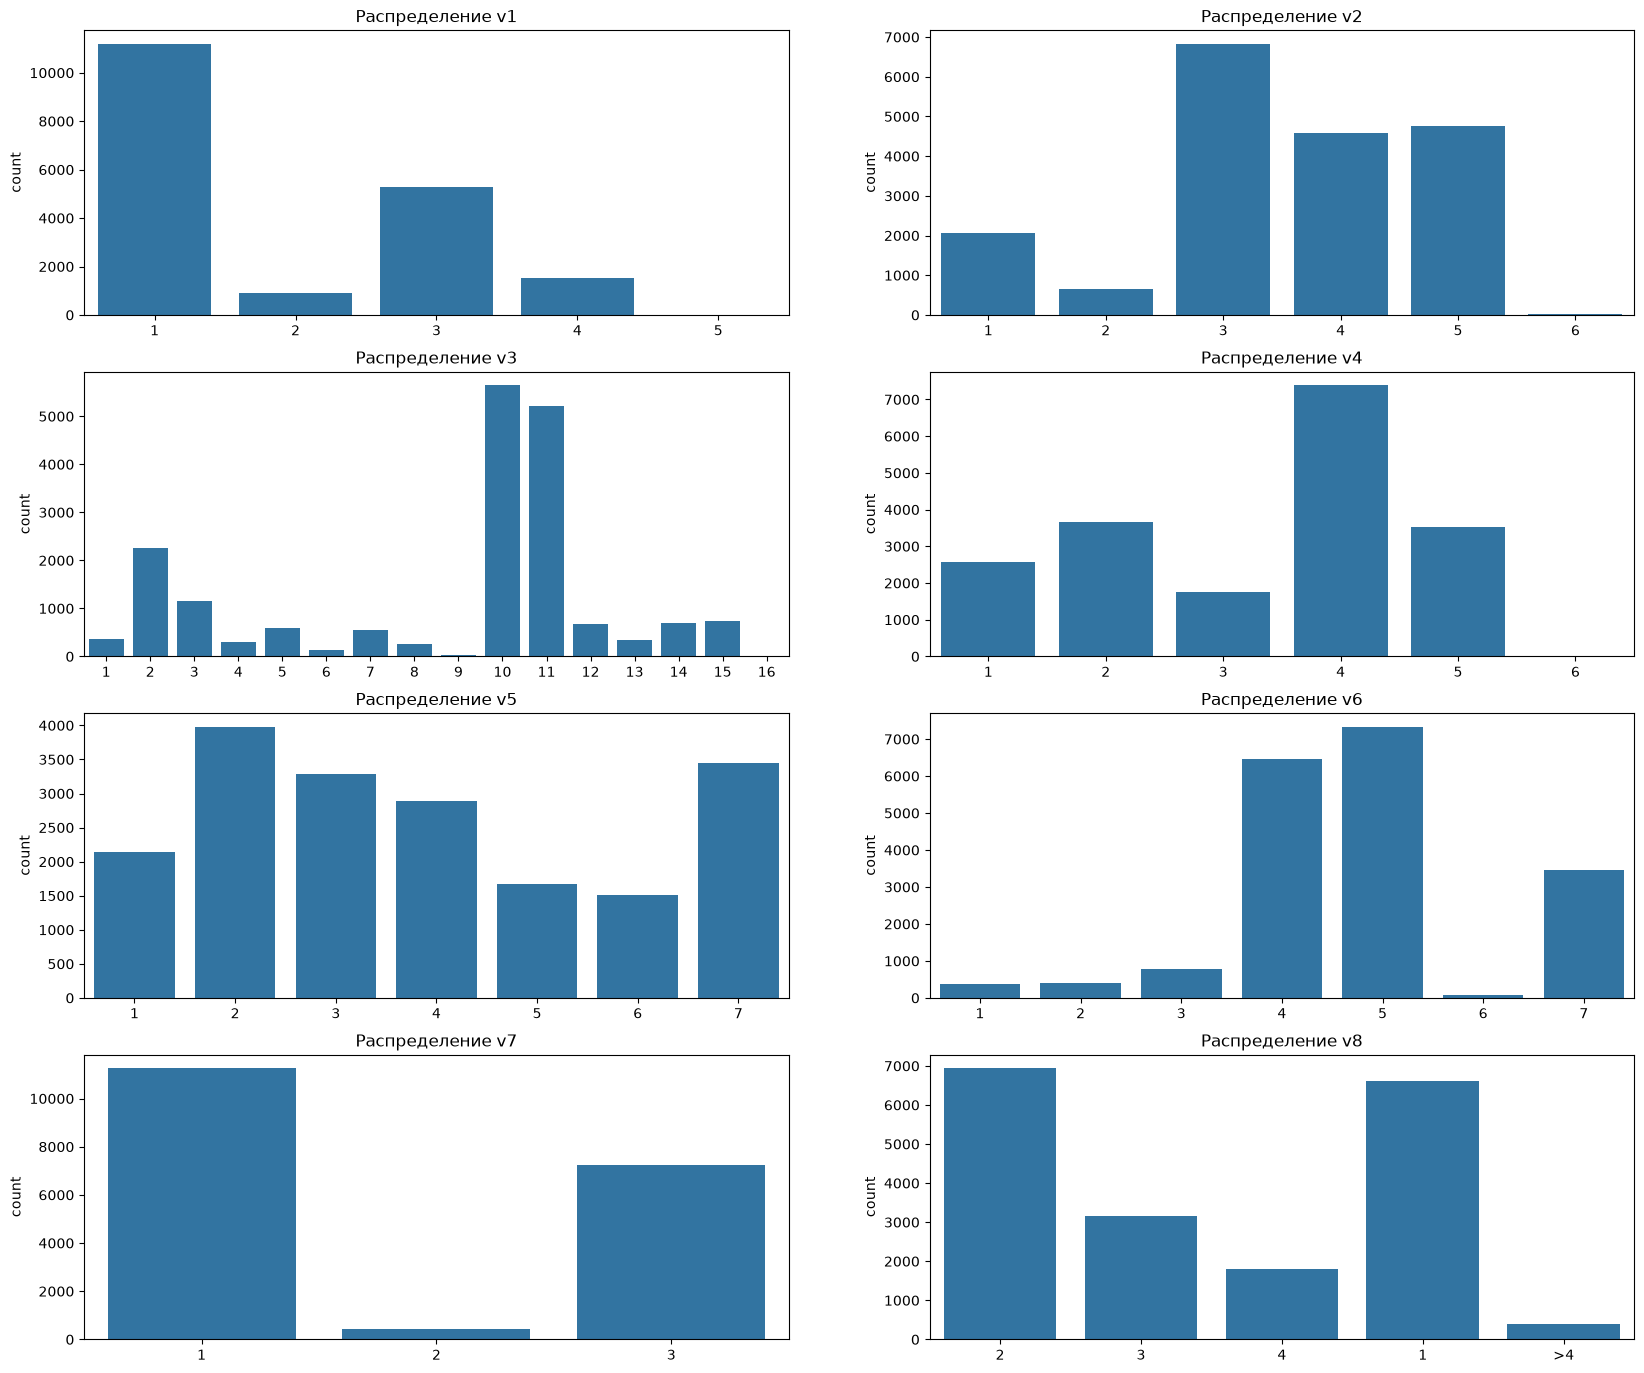

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 2, figsize = (20, 17))
axes = axes.flatten()
for i, v in enumerate([f'v{i}' for i in range(1, 9)]):
    sns.countplot(data = df, x = df[v], ax=axes[i])
    axes[i].set_title(f'Распределение {v}')
    axes[i].set_xlabel('')

plt.show()

На графиках мы видим тоже самое, что и в числовом варианте, поэтому перейдем к анализу этих признаков относительно целевой переменной.
Посмотрим на частоту дефолтов в каждом из признаков по классам

In [39]:
for v in [f'v{i}' for i in range(1, 9)]:
    print(df.groupby(v)['default'].agg(['count', 'sum', 'mean']))


    count   sum      mean
v1                       
1   11190  1372  0.122609
2     896   103  0.114955
3    5286  1452  0.274688
4    1536   276  0.179688
5       9     3  0.333333
    count   sum      mean
v2                       
1    2069   220  0.106332
2     659    67  0.101669
3    6827  1268  0.185733
4    4576   595  0.130026
5    4755  1053  0.221451
6      31     3  0.096774
    count   sum      mean
v3                       
1     365    47  0.128767
2    2260   417  0.184513
3    1145   248  0.216594
4     300    50  0.166667
5     585    39  0.066667
6     134    22  0.164179
7     544    53  0.097426
8     252    47  0.186508
9      22     3  0.136364
10   5643  1139  0.201843
11   5220   717  0.137356
12    684    55  0.080409
13    336    70  0.208333
14    692   173  0.250000
15    734   126  0.171662
16      1     0  0.000000
    count   sum      mean
v4                       
1    2581   431  0.166990
2    3673   686  0.186768
3    1763   339  0.192286
4    7383  1

Здесь ситуация уже более равномерная, равного перекоса в группах в распределениях дефолта нет. Посмотрим графики, что увидеть картину более наглядно